In [ ]:
import pandas as pd

# Fixed the Unicode escape error by using a raw string (r"...")
# Note: pd.read_excel cannot read .pdf files directly. If this is a PDF containing a table,
# you might need a different library like pdfplumber or tabula-py.
from google.colab import files
uploaded = files.upload()
df = pd.read_excel(next((iter(uploaded))))
display(df.head(10))
print(df.shape)
display(df.describe())

Saving GMM_Lab_Dataset_FINAL.xlsx to GMM_Lab_Dataset_FINAL (1).xlsx


,Record_ID,Feature_1,Feature_2
0,1,27.955,43.791
1,2,25.671,36.404
2,3,20.564,37.704
3,4,26.570,39.699
4,5,27.773,41.462
5,6,19.087,34.235
6,7,22.674,37.352
7,8,24.669,36.034
8,9,28.950,26.449
9,10,34.325,22.493


(450, 3)


,Record_ID,Feature_1,Feature_2
count,450.000000,450.000000,450.000000
mean,225.500000,26.209673,32.714913
std,130.048068,5.267977,6.495383
min,1.000000,16.274000,18.980000
25%,113.250000,20.771500,25.136500
50%,225.500000,26.837500,34.913000
75%,337.750000,30.770000,37.783250
max,450.000000,37.428000,44.637000


In [ ]:
# Once uploaded, you can load your file using the appropriate pandas function.
# Replace 'your_uploaded_file.csv' with the actual filename printed above.
# If it is an Excel file, use pd.read_excel('filename.xlsx')
# If it is a CSV file, use pd.read_csv('filename.csv')

# import pandas as pd
# df = pd.read_csv('your_uploaded_file.csv')
# display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'your_uploaded_file.csv'

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from matplotlib.patches import Ellipse


print("First 10 records:")
# Display dataset shape
print("\nDataset Shape:")
print(df.shape)

# Basic descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe())

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

First 10 records:

Dataset Shape:
(450, 3)

Descriptive Statistics:


,Record_ID,Feature_1,Feature_2
count,450.000000,450.000000,450.000000
mean,225.500000,26.209673,32.714913
std,130.048068,5.267977,6.495383
min,1.000000,16.274000,18.980000
25%,113.250000,20.771500,25.136500
50%,225.500000,26.837500,34.913000
75%,337.750000,30.770000,37.783250
max,450.000000,37.428000,44.637000



Column Names:
['Record_ID', 'Feature_1', 'Feature_2']


In [ ]:
numeric_columns = df.select_dtypes(include=np.number).columns

print("\nNumerical Columns:")
print(numeric_columns.tolist())

feature1 = numeric_columns[0]
feature2 = numeric_columns[1]

X = df[[feature1, feature2]].values

print(f"\nSelected Features: {feature1}, {feature2}")


Numerical Columns:
['Record_ID', 'Feature_1', 'Feature_2']

Selected Features: Record_ID, Feature_1


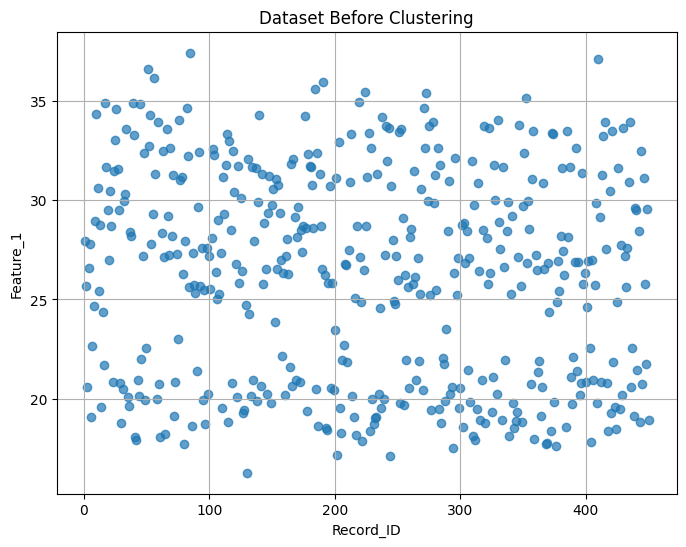

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(X[:, 0], X[:, 1], alpha=0.7)

plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title("Dataset Before Clustering")
plt.grid(True)
plt.show()

In [ ]:
gmm = GaussianMixture(
    n_components=3,
    covariance_type='full',
    random_state=42,
    max_iter=100
)

gmm.fit(X)

# Cluster assignment
gmm_labels = gmm.predict(X)

print("GMM Cluster Assignments:")
print(gmm_labels)


# Add cluster labels to dataframe
df['GMM_Cluster'] = gmm_labels

print("\nDataset with GMM Cluster:")
display(df.head(10))

GMM Cluster Assignments:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1]

Dataset with GMM Cluster:


,Record_ID,Feature_1,Feature_2,GMM_Cluster
0,1,27.955,43.791,2
1,2,25.671,36.404,2
2,3,20.564,37.704,2
3,4,26.570,39.699,2
4,5,27.773,41.462,2
5,6,19.087,34.235,2
6,7,22.674,37.352,2
7,8,24.669,36.034,2
8,9,28.950,26.449,2
9,10,34.325,22.493,2


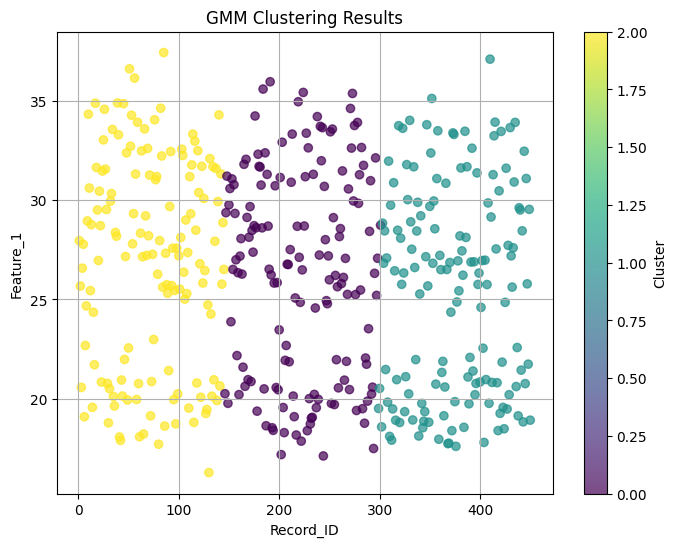

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=gmm_labels,
    cmap='viridis',
    alpha=0.7
)

plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title("GMM Clustering Results")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()

In [ ]:
print("Estimated Gaussian Means:")
print(gmm.means_)

print("\nCovariance Matrices:")
print(gmm.covariances_)

print("\nMixture Weights:")
print(gmm.weights_)

print("\nSum of Mixture Weights:")
print(gmm.weights_.sum())


Estimated Gaussian Means:
[[223.47986033  26.26854723]
 [372.42084631  25.41284928]
 [ 76.58595199  26.96626687]]

Covariance Matrices:
[[[3011.49715266   -9.44642646]
  [  -9.44642646   27.62297819]]

 [[2330.66840655    8.26528359]
  [   8.26528359   27.19623397]]

 [[2221.97247521   -3.92319383]
  [  -3.92319383   27.03984036]]]

Mixture Weights:
[0.34433893 0.33239066 0.32327041]

Sum of Mixture Weights:
1.0


In [ ]:
membership_probabilities = gmm.predict_proba(X)

probability_df = pd.DataFrame(
    membership_probabilities,
    columns=[
        "Component_1",
        "Component_2",
        "Component_3"
    ]
)

print("Membership Probabilities:")
display(probability_df.head(10))

Membership Probabilities:


,Component_1,Component_2,Component_3
0,0.000879,3.911682e-13,0.999121
1,0.000925,5.709132e-13,0.999075
2,0.001003,1.140335e-12,0.998997
3,0.000998,6.645568e-13,0.999002
4,0.001032,6.603200e-13,0.998968
5,0.001150,1.951502e-12,0.998850
6,0.001157,1.486430e-12,0.998843
7,0.001187,1.352881e-12,0.998813
8,0.001208,9.614911e-13,0.998792
9,0.001246,6.105092e-13,0.998754


In [ ]:
max_probability = membership_probabilities.max(axis=1)

df['Max_Membership_Probability'] = max_probability

print("Observations with lowest maximum membership probability:")

uncertain_indices = np.argsort(max_probability)[:10]

display(
    df.iloc[
        uncertain_indices
    ][[
        feature1,
        feature2,
        'GMM_Cluster',
        'Max_Membership_Probability'
    ]]
)

Observations with lowest maximum membership probability:


,Record_ID,Feature_1,GMM_Cluster,Max_Membership_Probability
302,303,28.837,1,0.503134
146,147,29.364,0,0.503818
147,148,31.204,0,0.513669
144,145,26.508,2,0.516585
298,299,19.503,1,0.518985
145,146,20.247,0,0.520505
300,301,28.735,0,0.524519
299,300,20.513,1,0.525490
303,304,26.820,1,0.533538
304,305,28.450,1,0.534659


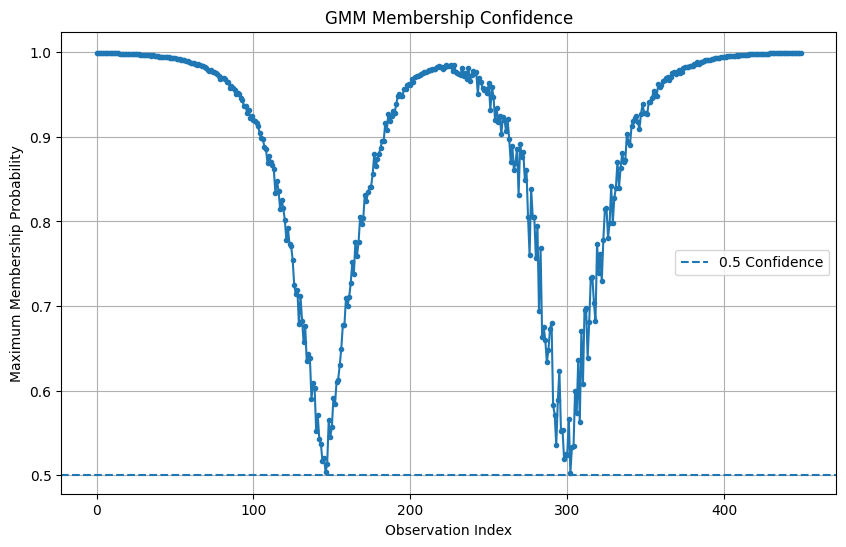

In [ ]:

plt.figure(figsize=(10, 6))

plt.plot(
    range(len(X)),
    max_probability,
    marker='o',
    linestyle='-',
    markersize=3
)

plt.axhline(
    0.5,
    linestyle='--',
    label='0.5 Confidence'
)

plt.xlabel("Observation Index")
plt.ylabel("Maximum Membership Probability")
plt.title("GMM Membership Confidence")
plt.legend()
plt.grid(True)
plt.show()

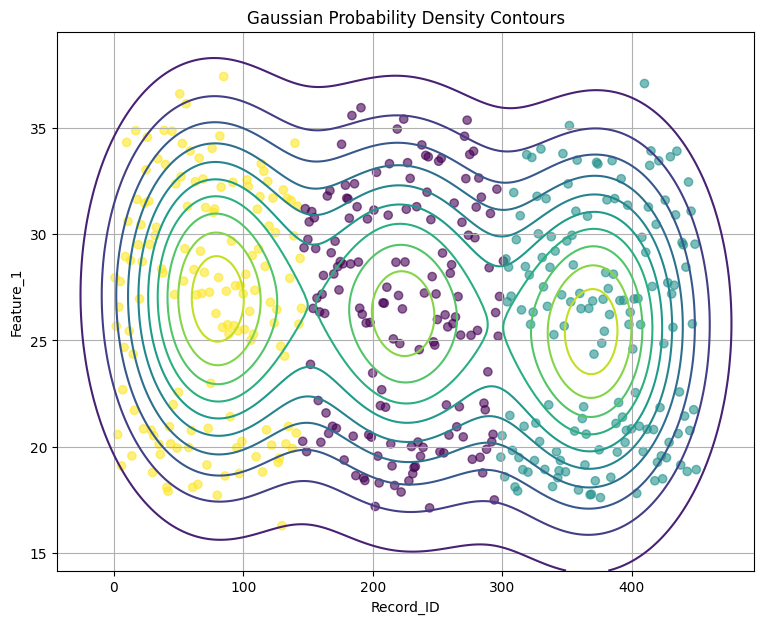

In [ ]:
x_min, x_max = X[:, 0].min(), X[:, 0].max()
y_min, y_max = X[:, 1].min(), X[:, 1].max()

x_range = x_max - x_min
y_range = y_max - y_min

xx, yy = np.meshgrid(
    np.linspace(
        x_min - 0.1 * x_range,
        x_max + 0.1 * x_range,
        200
    ),
    np.linspace(
        y_min - 0.1 * y_range,
        y_max + 0.1 * y_range,
        200
    )
)

grid = np.column_stack([xx.ravel(), yy.ravel()])

# Probability density
density = np.exp(gmm.score_samples(grid))
density = density.reshape(xx.shape)

plt.figure(figsize=(9, 7))

plt.contour(
    xx,
    yy,
    density,
    levels=10
)

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=gmm_labels,
    cmap='viridis',
    alpha=0.6
)

plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title("Gaussian Probability Density Contours")
plt.grid(True)
plt.show()

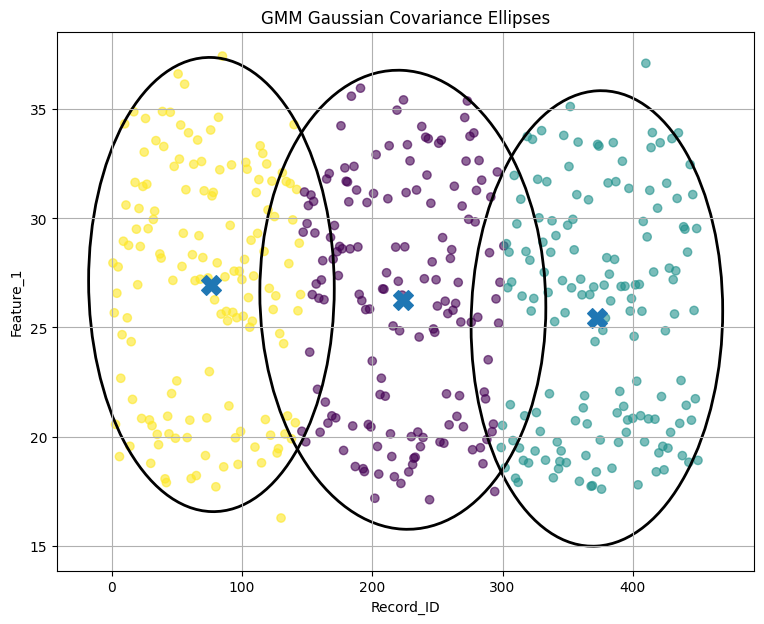

In [ ]:
def plot_covariance_ellipse(mean, covariance, ax, n_std=2.0):

    eigenvalues, eigenvectors = np.linalg.eigh(covariance)

    # Sort eigenvalues
    order = eigenvalues.argsort()[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    # Angle of ellipse
    angle = np.degrees(
        np.arctan2(
            eigenvectors[1, 0],
            eigenvectors[0, 0]
        )
    )

    # Width and height
    width, height = (
        2 * n_std * np.sqrt(eigenvalues)
    )

    ellipse = Ellipse(
        xy=mean,
        width=width,
        height=height,
        angle=angle,
        fill=False,
        linewidth=2
    )

    ax.add_patch(ellipse)


fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    X[:, 0],
    X[:, 1],
    c=gmm_labels,
    cmap='viridis',
    alpha=0.6
)

for i in range(3):
    plot_covariance_ellipse(
        gmm.means_[i],
        gmm.covariances_[i],
        ax,
        n_std=2
    )

ax.scatter(
    gmm.means_[:, 0],
    gmm.means_[:, 1],
    marker='X',
    s=200
)

ax.set_xlabel(feature1)
ax.set_ylabel(feature2)
ax.set_title("GMM Gaussian Covariance Ellipses")
ax.grid(True)

plt.show()


Iterations: [1, 2, 5, 10, 20, 50, 100]
Log-Likelihood: [np.float64(-9.266710264410595), np.float64(-9.254530108037837), np.float64(-9.251233489071756), np.float64(-9.251233489071756), np.float64(-9.251233489071756), np.float64(-9.251233489071756), np.float64(-9.251233489071756)]


/usr/local/lib/python3.13/dist-packages/sklearn/mixture/_base.py:269: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/mixture/_base.py:269: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


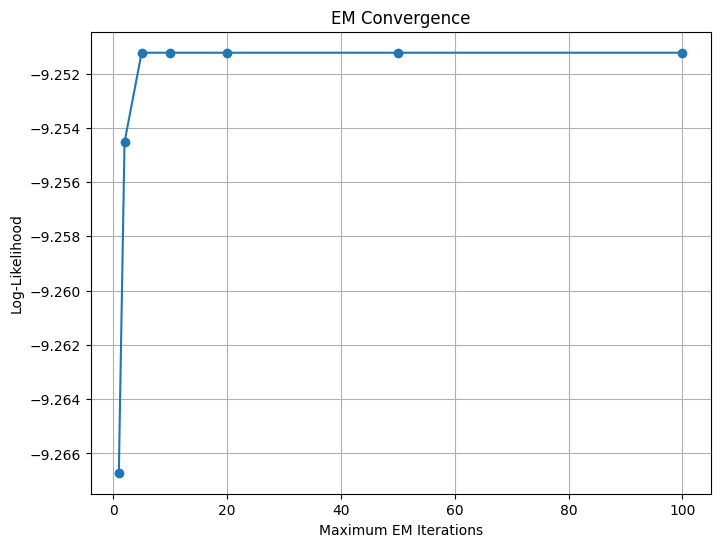

In [ ]:
iteration_values = [1, 2, 5, 10, 20, 50, 100]

log_likelihoods = []

for iterations in iteration_values:

    model = GaussianMixture(
        n_components=3,
        covariance_type='full',
        max_iter=iterations,
        random_state=42
    )

    model.fit(X)

    log_likelihoods.append(model.lower_bound_)


print("Iterations:", iteration_values)
print("Log-Likelihood:", log_likelihoods)


plt.figure(figsize=(8, 6))

plt.plot(
    iteration_values,
    log_likelihoods,
    marker='o'
)

plt.xlabel("Maximum EM Iterations")
plt.ylabel("Log-Likelihood")
plt.title("EM Convergence")
plt.grid(True)
plt.show()


In [ ]:
components = range(1, 9)

aic_values = []
bic_values = []

gmm_models = []

for k in components:

    model = GaussianMixture(
        n_components=k,
        covariance_type='full',
        random_state=42
    )

    model.fit(X)

    aic_values.append(model.aic(X))
    bic_values.append(model.bic(X))

    gmm_models.append(model)


# Create results table
model_results = pd.DataFrame({
    'Components': list(components),
    'AIC': aic_values,
    'BIC': bic_values
})

print("AIC and BIC Results:")
display(model_results)

AIC and BIC Results:


,Components,AIC,BIC
0,1,8432.913615,8453.459853
1,2,8376.382563,8421.584287
2,3,8359.682867,8429.540076
3,4,8355.805366,8450.318060
4,5,8355.893613,8475.061793
5,6,8361.007722,8504.831387
6,7,8363.637762,8532.116913
7,8,8375.391295,8568.525932


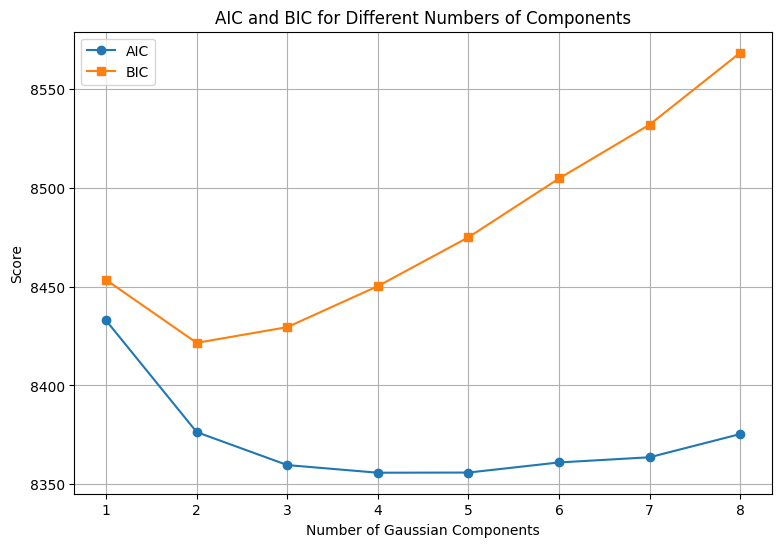

Best number of components according to AIC: 4
Best number of components according to BIC: 2


In [ ]:
plt.figure(figsize=(9, 6))

plt.plot(
    components,
    aic_values,
    marker='o',
    label='AIC'
)

plt.plot(
    components,
    bic_values,
    marker='s',
    label='BIC'
)

plt.xlabel("Number of Gaussian Components")
plt.ylabel("Score")
plt.title("AIC and BIC for Different Numbers of Components")
plt.xticks(list(components))
plt.legend()
plt.grid(True)
plt.show()


# Best component according to AIC and BIC
best_aic = components[np.argmin(aic_values)]
best_bic = components[np.argmin(bic_values)]

print("Best number of components according to AIC:", best_aic)
print("Best number of components according to BIC:", best_bic)


In [ ]:
selected_k = best_bic

print("\nSelected number of clusters:", selected_k)




Selected number of clusters: 2


In [ ]:
final_gmm = GaussianMixture(
    n_components=selected_k,
    covariance_type='full',
    random_state=42
)

final_gmm.fit(X)

final_gmm_labels = final_gmm.predict(X)

print("Final GMM cluster assignments:")
print(final_gmm_labels)




Final GMM cluster assignments:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1]


In [ ]:
kmeans = KMeans(
    n_clusters=selected_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X)

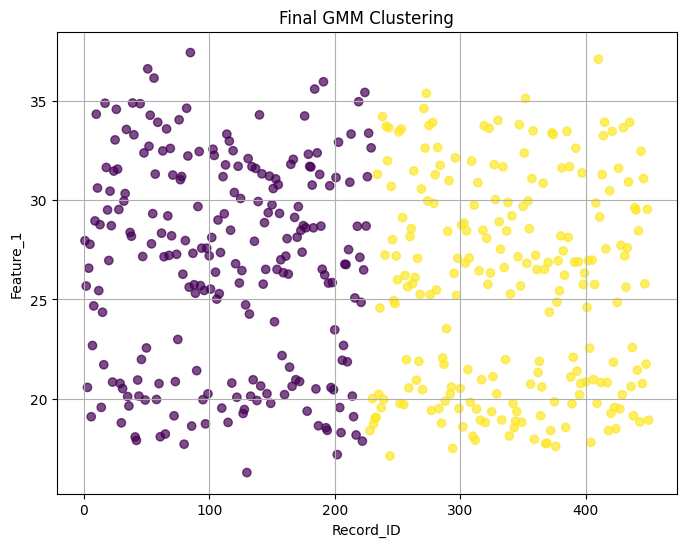

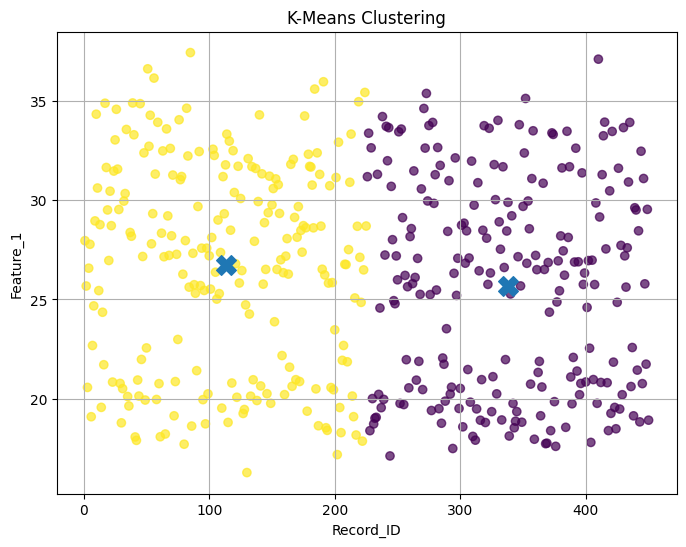

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=final_gmm_labels,
    cmap='viridis',
    alpha=0.7
)

plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title("Final GMM Clustering")
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    alpha=0.7
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=200
)

plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title("K-Means Clustering")
plt.grid(True)
plt.show()


In [ ]:
gmm_silhouette = silhouette_score(
    X,
    final_gmm_labels
)

kmeans_silhouette = silhouette_score(
    X,
    kmeans_labels
)

print("GMM Silhouette Score:",
      gmm_silhouette)

print("K-Means Silhouette Score:",
      kmeans_silhouette)


GMM Silhouette Score: 0.6216051561766253
K-Means Silhouette Score: 0.6217931585993534


In [ ]:
# Create three observations using values within
# the approximate range of the dataset

new_observations = np.array([
    [
        np.mean(X[:, 0]),
        np.mean(X[:, 1])
    ],
    [
        np.percentile(X[:, 0], 25),
        np.percentile(X[:, 1], 25)
    ],
    [
        np.percentile(X[:, 0], 75),
        np.percentile(X[:, 1], 75)
    ]
])

print("New Observations:")
print(new_observations)

New Observations:
[[225.5         26.20967333]
 [113.25        20.7715    ]
 [337.75        30.77      ]]


In [ ]:
new_labels = final_gmm.predict(new_observations)

new_probabilities = final_gmm.predict_proba(
    new_observations
)

print("\nPredicted Components:")
print(new_labels)

print("\nMembership Probabilities:")
print(new_probabilities)



Predicted Components:
[0 0 1]

Membership Probabilities:
[[0.51259794 0.48740206]
 [0.99113943 0.00886057]
 [0.00901631 0.99098369]]


In [ ]:
new_results = pd.DataFrame(
    new_observations,
    columns=[feature1, feature2]
)

new_results['Predicted_Component'] = new_labels

new_results['Confidence'] = (
    new_probabilities.max(axis=1)
)

print("\nNew Observation Predictions:")
display(new_results)


New Observation Predictions:


,Record_ID,Feature_1,Predicted_Component,Confidence
0,225.50,26.209673,0,0.512598
1,113.25,20.771500,0,0.991139
2,337.75,30.770000,1,0.990984


In [ ]:
covariance_types = [
    'full',
    'tied',
    'diag',
    'spherical'
]

covariance_results = []

for cov_type in covariance_types:

    model = GaussianMixture(
        n_components=selected_k,
        covariance_type=cov_type,
        random_state=42
    )

    model.fit(X)

    labels = model.predict(X)

    score = silhouette_score(
        X,
        labels
    )

    covariance_results.append({
        'Covariance Type': cov_type,
        'AIC': model.aic(X),
        'BIC': model.bic(X),
        'Silhouette Score': score
    })


covariance_df = pd.DataFrame(
    covariance_results
)

print("Comparison of Covariance Types:")
display(covariance_df)


Comparison of Covariance Types:


,Covariance Type,AIC,BIC,Silhouette Score
0,full,8376.382563,8421.584287,0.621605
1,tied,8370.468495,8403.342476,0.621300
2,diag,8372.546813,8409.530041,0.620150
3,spherical,10054.776893,10083.541626,0.621786


In [ ]:

print("FINAL SUMMARY")
print("Number of observations:", len(X))
print("Features used:", feature1, "and", feature2)
print("AIC preferred components:", best_aic)
print("BIC preferred components:", best_bic)
print("Selected components:", selected_k)
print("GMM Silhouette Score:",
      round(gmm_silhouette, 4))
print("K-Means Silhouette Score:",
      round(kmeans_silhouette, 4))
print("\nGMM provides soft/probabilistic membership,")
print("while K-Means provides hard cluster assignments.")
print("\nMixture weights:")
print(final_gmm.weights_)
print("\nSum of mixture weights:",
      final_gmm.weights_.sum())

FINAL SUMMARY
Number of observations: 450
Features used: Record_ID and Feature_1
AIC preferred components: 4
BIC preferred components: 2
Selected components: 2
GMM Silhouette Score: 0.6216
K-Means Silhouette Score: 0.6218

GMM provides soft/probabilistic membership,
while K-Means provides hard cluster assignments.

Mixture weights:
[0.50197372 0.49802628]

Sum of mixture weights: 1.0
